# 🕵️ El Detective de Señales
**Clasificación automática de modulaciones (ASK, FSK, PSK, QAM) con Deep Learning**

Proyecto en 3 fases:
1. **Fase 1** – Generación y exploración del dataset de señales moduladas con ruido.
2. **Fase 2** – Diseño y entrenamiento de una red neuronal convolucional 1D (Keras/TensorFlow).
3. **Fase 3** – Evaluación: matriz de confusión, precisión vs. ruido (SNR) y conclusiones.

## 🔹 Fase 1: Generación del dataset

Cada señal se representa en **banda base compleja** con dos canales: **I** (parte real) y **Q** (parte imaginaria).
Cada señal tiene 128 símbolos × 8 muestras/símbolo = 1024 muestras. Se le agrega ruido AWGN con SNR aleatoria entre -4 y 20 dB.

| Clase | Variantes incluidas |
|-------|--------------------|
| ASK | OOK (2-ASK) y 4-ASK |
| FSK | 2-FSK y 4-FSK |
| PSK | BPSK, QPSK y 8-PSK |
| QAM | 16-QAM y 64-QAM |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
os.makedirs('results', exist_ok=True)

CLASES = ["ASK", "FSK", "PSK", "QAM"]
SPS = 8            # muestras por símbolo
N_SIMBOLOS = 128   # símbolos por señal
N_MUESTRAS = SPS * N_SIMBOLOS  # 1024 muestras por señal


def _normalizar(x):
    """Potencia promedio = 1."""
    return x / np.sqrt(np.mean(np.abs(x) ** 2))


def gen_ask(rng):
    M = rng.choice([2, 4])                       # OOK / 4-ASK
    niveles = np.linspace(0, 1, M)
    simbolos = rng.choice(niveles, N_SIMBOLOS)
    return np.repeat(simbolos, SPS).astype(complex)


def gen_fsk(rng):
    M = rng.choice([2, 4])                       # 2-FSK / 4-FSK
    desviacion = rng.uniform(0.04, 0.10)         # frecuencia normalizada (ciclos/muestra)
    freqs = (np.arange(M) - (M - 1) / 2) * 2 * desviacion
    simbolos = rng.choice(freqs, N_SIMBOLOS)
    f_inst = np.repeat(simbolos, SPS)
    fase = 2 * np.pi * np.cumsum(f_inst)         # fase continua
    return np.exp(1j * fase)


def gen_psk(rng):
    M = rng.choice([2, 4, 8])                    # BPSK / QPSK / 8-PSK
    fases = 2 * np.pi * rng.integers(0, M, N_SIMBOLOS) / M
    return np.repeat(np.exp(1j * fases), SPS)


def gen_qam(rng):
    M = rng.choice([16, 64])                     # 16-QAM / 64-QAM
    L = int(np.sqrt(M))
    niveles = np.arange(-(L - 1), L, 2)
    I = rng.choice(niveles, N_SIMBOLOS)
    Q = rng.choice(niveles, N_SIMBOLOS)
    return np.repeat(I + 1j * Q, SPS)


GENERADORES = {"ASK": gen_ask, "FSK": gen_fsk, "PSK": gen_psk, "QAM": gen_qam}


def agregar_ruido(x, snr_db, rng):
    """Ruido blanco gaussiano (AWGN) para una SNR dada en dB."""
    p_ruido = 10 ** (-snr_db / 10)
    ruido = np.sqrt(p_ruido / 2) * (rng.standard_normal(x.size) + 1j * rng.standard_normal(x.size))
    return x + ruido


def generar_senal(clase, snr_db, rng):
    x = GENERADORES[clase](rng)
    x = x * np.exp(1j * rng.uniform(0, 2 * np.pi))   # fase inicial aleatoria
    x = _normalizar(x)
    return agregar_ruido(x, snr_db, rng)


def generar_dataset(n_por_clase=1500, snr_min=-4, snr_max=20, semilla=42):
    """Devuelve X (N, 1024, 2) con canales I/Q, y (N,), snr (N,)."""
    rng = np.random.default_rng(semilla)
    X, y, snrs = [], [], []
    for idx, clase in enumerate(CLASES):
        for _ in range(n_por_clase):
            snr = rng.uniform(snr_min, snr_max)
            s = generar_senal(clase, snr, rng)
            X.append(np.stack([s.real, s.imag], axis=-1))
            y.append(idx)
            snrs.append(snr)
    X = np.array(X, dtype=np.float32)
    y = np.array(y)
    snrs = np.array(snrs, dtype=np.float32)
    perm = rng.permutation(len(y))
    return X[perm], y[perm], snrs[perm]

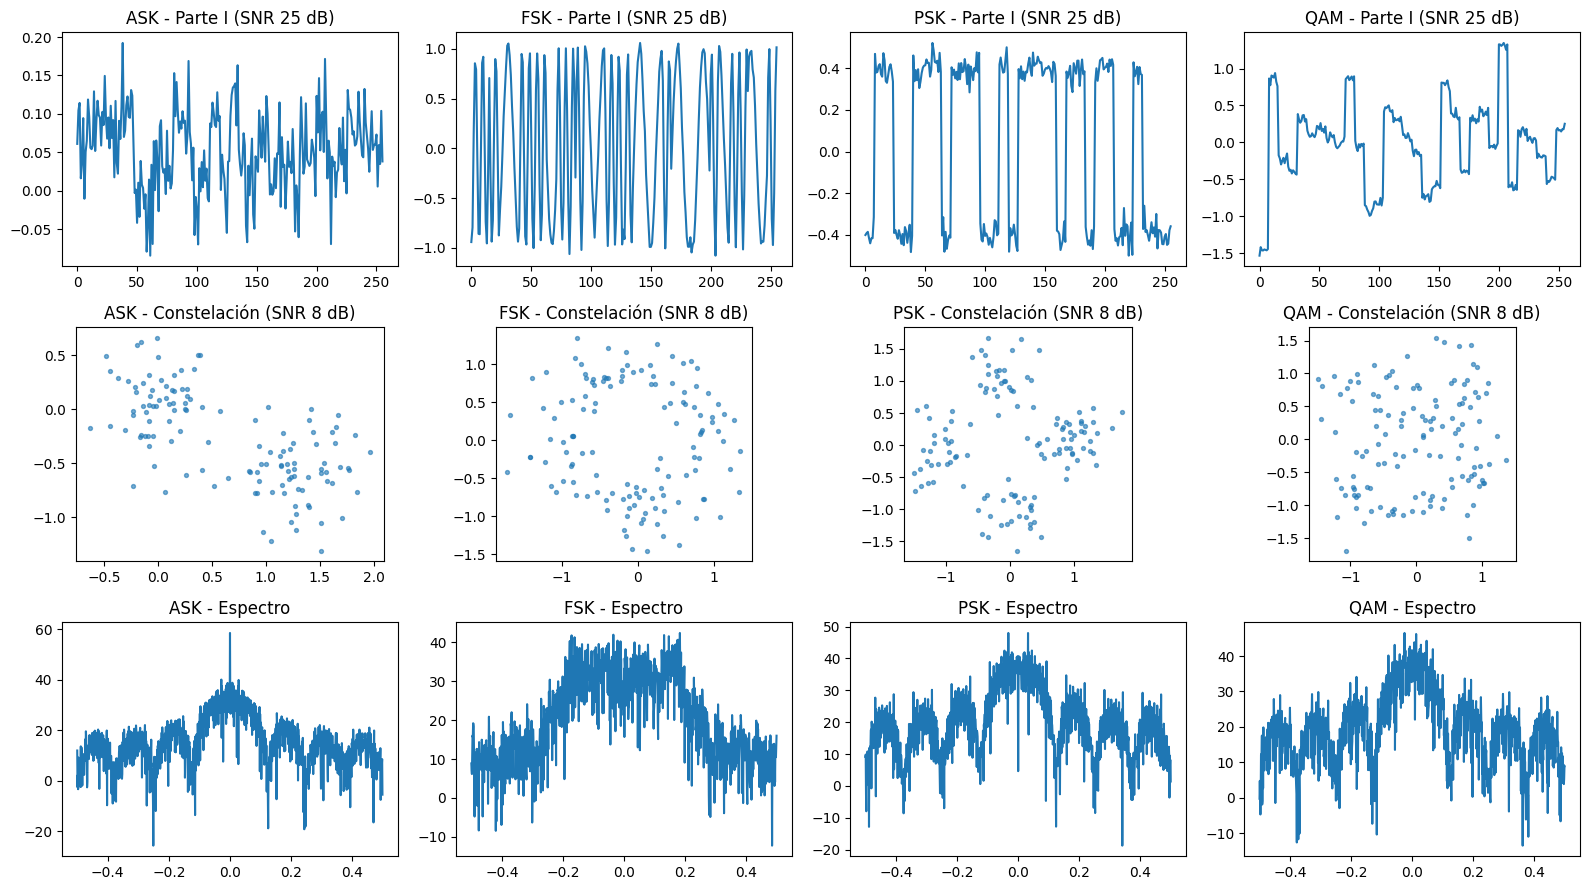

In [2]:
# --- Visualización de una señal de cada clase ---
rng = np.random.default_rng(7)
fig, axs = plt.subplots(3, 4, figsize=(16, 9))
for j, clase in enumerate(CLASES):
    s_limpia = generar_senal(clase, 25, rng)   # casi sin ruido
    s_ruidosa = generar_senal(clase, 8, rng)   # con ruido

    axs[0, j].plot(s_limpia.real[:256]); axs[0, j].set_title(f"{clase} - Parte I (SNR 25 dB)")
    axs[1, j].scatter(s_ruidosa.real[::SPS], s_ruidosa.imag[::SPS], s=8, alpha=.6)
    axs[1, j].set_title(f"{clase} - Constelación (SNR 8 dB)"); axs[1, j].set_aspect('equal')
    espectro = 20*np.log10(np.abs(np.fft.fftshift(np.fft.fft(s_limpia))) + 1e-9)
    axs[2, j].plot(np.linspace(-.5, .5, len(espectro)), espectro); axs[2, j].set_title(f"{clase} - Espectro")
plt.tight_layout()
plt.savefig('results/01_ejemplos_senales.png', dpi=150)
plt.show()

In [3]:
# --- Generar dataset completo y dividir en train / val / test ---
from sklearn.model_selection import train_test_split

X, y, snrs = generar_dataset(n_por_clase=1500, snr_min=-4, snr_max=20)
print("Forma de X:", X.shape, "| Forma de y:", y.shape)

X_tmp, X_test, y_tmp, y_test, s_tmp, s_test = train_test_split(X, y, snrs, test_size=0.15, stratify=y, random_state=1)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.15, stratify=y_tmp, random_state=1)
print(f"Train: {len(y_train)} | Val: {len(y_val)} | Test: {len(y_test)}")

Forma de X: (6000, 1024, 2) | Forma de y: (6000,)
Train: 4335 | Val: 765 | Test: 900


## 🔹 Fase 2: Red neuronal (CNN 1D)

Se usa una **CNN 1D** porque las convoluciones aprenden patrones locales en la señal
(cambios de amplitud, frecuencia o fase) sin tener que extraer características a mano.
Arquitectura: 4 bloques `Conv1D + BatchNorm + MaxPool` → `GlobalAveragePooling` → `Dense` → `Softmax` (4 clases).

In [4]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)

def crear_modelo(n_muestras=1024, n_clases=4):
    entrada = keras.Input(shape=(n_muestras, 2))
    x = entrada
    for filtros, kernel in [(32, 7), (64, 5), (128, 3), (128, 3)]:
        x = layers.Conv1D(filtros, kernel, padding='same', activation='relu')(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling1D(2)(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    salida = layers.Dense(n_clases, activation='softmax')(x)
    return keras.Model(entrada, salida, name="detective_de_senales")

modelo = crear_modelo()
modelo.compile(optimizer=keras.optimizers.Adam(1e-3),
               loss='sparse_categorical_crossentropy', metrics=['accuracy'])
modelo.summary()

Model: "detective_de_senales"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 1024, 2)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 1024, 32)       │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 512, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 512, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 256, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 256, 128)       │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 128, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 128, 128)       │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 64, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 94,692 (369.89 KB)

 Trainable params: 93,988 (367.14 KB)

 Non-trainable params: 704 (2.75 KB)

Epoch 1/40
68/68 ━━━━━━━━━━━━━━━━━━━━ 38s 293ms/step - accuracy: 0.8616 - loss: 0.3670 - val_accuracy: 0.5333 - val_loss: 1.0842 - learning_rate: 0.0010
Epoch 2/40
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9696 - loss: 0.0876 - val_accuracy: 0.8288 - val_loss: 0.4792 - learning_rate: 0.0010
Epoch 3/40
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9873 - loss: 0.0408 - val_accuracy: 0.9739 - val_loss: 0.1394 - learning_rate: 0.0010
Epoch 4/40
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9894 - loss: 0.0310 - val_accuracy: 0.9961 - val_loss: 0.0379 - learning_rate: 0.0010
Epoch 5/40
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9977 - loss: 0.0140 - val_accuracy: 0.9948 - val_loss: 0.0185 - learning_rate: 0.0010
Epoch 6/40
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9977 - loss: 0.0108 - val_accuracy: 0.9908 - val_loss: 0.0257 - learning_rate: 0.0010
Epoch 7/40
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9970 - loss: 0.0111 - val_a

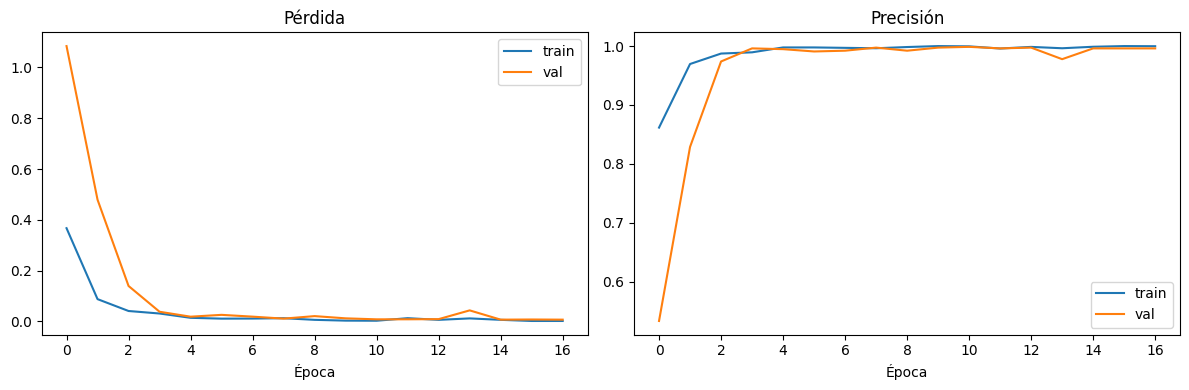

In [5]:
callbacks = [
    keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True, monitor='val_accuracy'),
    keras.callbacks.ReduceLROnPlateau(patience=3, factor=0.5, verbose=1),
]
historia = modelo.fit(X_train, y_train, validation_data=(X_val, y_val),
                      epochs=40, batch_size=64, callbacks=callbacks)

# Curvas de entrenamiento
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(historia.history['loss'], label='train'); ax[0].plot(historia.history['val_loss'], label='val')
ax[0].set_title('Pérdida'); ax[0].legend(); ax[0].set_xlabel('Época')
ax[1].plot(historia.history['accuracy'], label='train'); ax[1].plot(historia.history['val_accuracy'], label='val')
ax[1].set_title('Precisión'); ax[1].legend(); ax[1].set_xlabel('Época')
plt.tight_layout(); plt.savefig('results/02_curvas_entrenamiento.png', dpi=150); plt.show()

## 🔹 Fase 3: Evaluación

Se evalúa en el conjunto de **test** (datos que la red nunca vio). Lo más interesante: ver cómo cae la precisión cuando aumenta el ruido.

Precisión global en test: 99.22%

              precision    recall  f1-score   support

         ASK       1.00      1.00      1.00       225
         FSK       1.00      1.00      1.00       225
         PSK       0.98      0.99      0.98       225
         QAM       0.99      0.98      0.98       225

    accuracy                           0.99       900
   macro avg       0.99      0.99      0.99       900
weighted avg       0.99      0.99      0.99       900



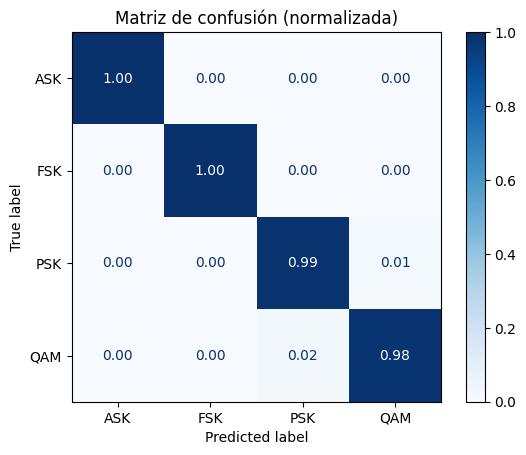

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

loss, acc = modelo.evaluate(X_test, y_test, verbose=0)
print(f"Precisión global en test: {acc*100:.2f}%\n")

y_pred = np.argmax(modelo.predict(X_test, verbose=0), axis=1)
print(classification_report(y_test, y_pred, target_names=CLASES))

cm = confusion_matrix(y_test, y_pred, normalize='true')
ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(cmap='Blues', values_format='.2f')
plt.title('Matriz de confusión (normalizada)')
plt.savefig('results/03_matriz_confusion.png', dpi=150); plt.show()

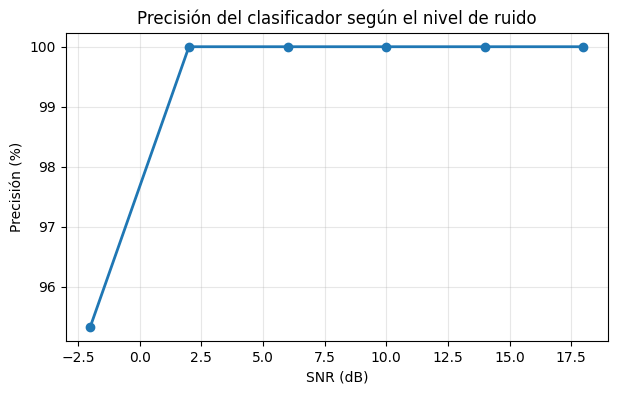

SNR ≈  -2.0 dB ->  95.3%
SNR ≈   2.0 dB -> 100.0%
SNR ≈   6.0 dB -> 100.0%
SNR ≈  10.0 dB -> 100.0%
SNR ≈  14.0 dB -> 100.0%
SNR ≈  18.0 dB -> 100.0%


In [7]:
# --- Precisión vs. SNR ---
bordes = np.arange(-4, 22, 4)   # -4, 0, 4, ..., 20
centros, accs = [], []
for a, b in zip(bordes[:-1], bordes[1:]):
    m = (s_test >= a) & (s_test < b + (1e-6 if b == bordes[-1] else 0))
    if m.sum() > 0:
        centros.append((a + b) / 2)
        accs.append((y_pred[m] == y_test[m]).mean() * 100)

plt.figure(figsize=(7, 4))
plt.plot(centros, accs, 'o-', linewidth=2)
plt.xlabel('SNR (dB)'); plt.ylabel('Precisión (%)'); plt.grid(alpha=.3)
plt.title('Precisión del clasificador según el nivel de ruido')
plt.savefig('results/04_precision_vs_snr.png', dpi=150); plt.show()
for c, a in zip(centros, accs): print(f"SNR ≈ {c:5.1f} dB -> {a:5.1f}%")

In [8]:
# --- Guardar el modelo ---
modelo.save('results/modelo_modulaciones.keras')
print("Modelo guardado en results/modelo_modulaciones.keras")

Modelo guardado en results/modelo_modulaciones.keras
